In [1]:
import pandas as pd

df = pd.read_csv("/content/G3.csv")

print(df.head())
print(df.shape)

  enterprise_group_id     display_name          enterprise_group_name  \
0         EG_03260722   Morgan Stanley                 MORGAN STANLEY   
1         EG_03256960  Bank of America    BANK OF AMERICA CORPORATION   
2         EG_01804232        Citigroup                 CITIGROUP INC.   
3         EG_02027196    Goldman Sachs  THE GOLDMAN SACHS GROUP, INC.   
4         EG_03266820          Siemens     Siemens Aktiengesellschaft   

         group_root_lei enterprise_group_jurisdiction  \
0  IGJSJL3JD5P30I6NJZ34                         US-DE   
1  9DJT3UXIJIZJI4WXO774                         US-DE   
2  6SHGI4ZSSLCXXQSBB395                         US-DE   
3  784F5XWPLTWKTBV3E584                         US-DE   
4  W38RGI023J3WT1HWRP32                            DE   

  enterprise_group_entity_status                       website company_type  \
0                         ACTIVE             morganstanley.com       PUBLIC   
1                         ACTIVE             bankofamerica.c

In [2]:
print(df.info())

print(df.columns)

print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1755 entries, 0 to 1754
Data columns (total 28 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   enterprise_group_id             1755 non-null   object 
 1   display_name                    1755 non-null   object 
 2   enterprise_group_name           1755 non-null   object 
 3   group_root_lei                  1755 non-null   object 
 4   enterprise_group_jurisdiction   1755 non-null   object 
 5   enterprise_group_entity_status  1755 non-null   object 
 6   website                         1716 non-null   object 
 7   company_type                    1753 non-null   object 
 8   employees                       1656 non-null   float64
 9   employees_year                  1655 non-null   float64
 10  revenue                         1654 non-null   float64
 11  revenue_currency                1654 non-null   object 
 12  revenue_year                    16

In [3]:
print(df.isnull().sum())

enterprise_group_id                 0
display_name                        0
enterprise_group_name               0
group_root_lei                      0
enterprise_group_jurisdiction       0
enterprise_group_entity_status      0
website                            39
company_type                        2
employees                          99
employees_year                    100
revenue                           101
revenue_currency                  101
revenue_year                      102
net_income                        156
net_income_currency               156
net_income_year                   156
market_cap                        531
market_cap_currency               528
market_cap_date                   531
legal_units_count                   0
direct_subsidiaries_count           8
max_hierarchy_depth                 8
is_standalone_entity                0
website_source                     35
employees_source                   91
revenue_source                     86
net_income_s

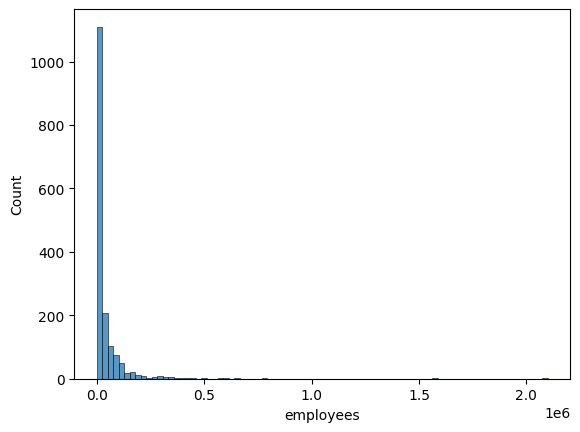

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(df["employees"])
plt.show()

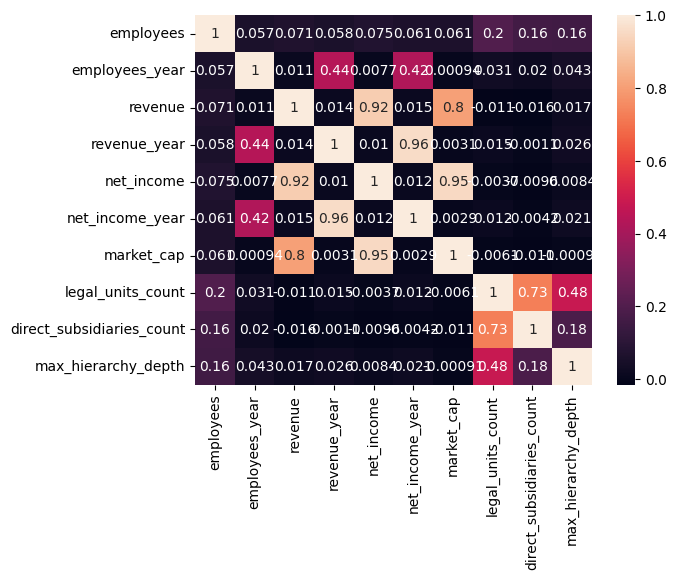

In [5]:
sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True
)
plt.show()

In [6]:
df.drop_duplicates(inplace=True)

In [7]:
num_cols = df.select_dtypes(include="number").columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

In [8]:
cat_cols = df.select_dtypes(include="object").columns

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [9]:
drop_cols = [
    "website",
    "website_source_url"
]

for col in drop_cols:
    if col in df.columns:
        df.drop(col, axis=1, inplace=True)

In [10]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

for col in df.select_dtypes(include="object").columns:
    df[col] = le.fit_transform(df[col].astype(str))

In [11]:
target = "company_type"

In [12]:
target = "entity_status"

In [17]:
from sklearn.model_selection import train_test_split

X = df.drop(target, axis=1)

y = df[target]

X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [19]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=1000)

lr.fit(X_train,y_train)

pred_lr = lr.predict(X_test)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [20]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier()

dt.fit(X_train,y_train)

pred_dt = dt.predict(X_test)

In [21]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier()

rf.fit(X_train,y_train)

pred_rf = rf.predict(X_test)

In [22]:
from sklearn.metrics import accuracy_score

print("Logistic Regression:",
      accuracy_score(y_test,pred_lr))

print("Decision Tree:",
      accuracy_score(y_test,pred_dt))

print("Random Forest:",
      accuracy_score(y_test,pred_rf))

Logistic Regression: 0.6951566951566952
Decision Tree: 0.8404558404558404
Random Forest: 0.9002849002849003


In [23]:
import joblib

joblib.dump(rf,"company_model.pkl")

['company_model.pkl']